# 05 · Selección del modelo, prueba única y registro

1. **Champion y challenger**: las dos mejores familias por PR-AUC por evento en la CV (versiones optimizadas del
   notebook 04 y candidatos del 03), con la pregunta de si la diferencia supera la variación entre pliegues.
2. **Modelos finales**: se entrenan con **todo** el período de entrenamiento (2018-01 → 2019-09) con el mismo protocolo
   (todas las fallas + 15 % de los discos sanos, semilla 42).
3. **Prueba única en noviembre de 2019** (después de un mes de embargo), con todas sus filas: PR-AUC y F0,5 por
   evento, discos vistos y no vistos en entrenamiento, anticipación. Las reglas de esta evaluación se fijaron antes de correrla (`docs/plan_evaluacion_final.md`); las rondas anteriores se declaran en las limitaciones.
4. **Métrica de negocio**: costo esperado por 1.000 SSD-mes con C_FP = 1 y C_FN = k, k ∈ [1, 50], frente a la regla
   de umbral; k de equilibrio. Los modelos se comparan **al mismo presupuesto de alertas** (compromiso del PSet #1): en
   la CV (predicciones out-of-fold) se elige cuántas alertas por 1.000 SSD-mes conviene emitir, y en la prueba cada
   modelo emite esa cantidad con sus scores más altos. El umbral de la prueba se busca **sin etiquetas** (contar
   alertas solo requiere disco, fecha y score), así que no hay fuga; y como depende del orden y no de la escala del
   score, no lo afecta que el modelo final se haya entrenado con más datos que los de la CV.
5. **Tiempos y explicabilidad** (valores SHAP).
6. **Model Registry**: `ssd-failure-modelo` con alias `@champion` y `@challenger`; `docs/corridas.csv`.

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src import datos, pipeline as pl, experimentos as exp

pd.set_option("display.width", 220, "display.max_columns", 40, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
DATOS = Path(os.environ.get("DATOS_DIR", "/datos"))
FIG = Path("../docs/figuras"); FIG.mkdir(parents=True, exist_ok=True)
SEMILLA, FRAC = pl.SEMILLA, 0.15
T0 = time.time()

mlflow = pl.configurar_mlflow()
from mlflow import MlflowClient
cliente = MlflowClient()
manifiesto = datos.leer_manifiesto(DATOS / "obt_mc1")
META_DATOS = datos.metadatos_dataset(DATOS / "obt_mc1")
eda = json.loads(Path("../docs/eda_decisiones.json").read_text())
print("commit:", pl.commit_git(), "· experimento:", pl.NOMBRE_EXPERIMENTO)

commit: 493d8365196f1e0cbf13b70a6b1e24f1c0cd72aa · experimento: ssd-failure-mc1


## 1. Champion y challenger según la CV

In [2]:
r03 = exp.resultados(DATOS / "oof" / "03")
r04 = exp.resultados(DATOS / "oof" / "04")
filas = []
for nombre, r in {**r03, **r04}.items():
    if r["fase"] == "baseline" or "sin_degradacion" in nombre:
        continue
    filas.append({"nombre": nombre, "familia": r["familia"], "fase": r["fase"], "run_id": r["run_id"],
                  "cv_media": r["cv_pr_auc_evento_media"], "cv_std": r["cv_pr_auc_evento_std"],
                  "train": r["train_pr_auc_evento"], "oof": str((DATOS / "oof" / ("04" if nombre in r04 else "03")) / f"{nombre}.parquet")})
ranking = pd.DataFrame(filas).sort_values("cv_media", ascending=False).set_index("nombre")
# Una sola versión por familia: la mejor (optimizada si el tuning mejoró)
por_familia = ranking.groupby("familia", sort=False).head(1)
CHAMPION, CHALLENGER = por_familia.index[0], por_familia.index[1]
c, d = por_familia.loc[CHAMPION], por_familia.loc[CHALLENGER]
diferencia = c["cv_media"] - d["cv_media"]
print(f"Champion: {CHAMPION} (CV {c['cv_media']:.4f} ± {c['cv_std']:.4f})")
print(f"Challenger: {CHALLENGER} (CV {d['cv_media']:.4f} ± {d['cv_std']:.4f})")
print(f"Diferencia {diferencia:.4f} {'>' if diferencia > max(c['cv_std'], d['cv_std']) else '≤'} "
      f"la std entre pliegues ({max(c['cv_std'], d['cv_std']):.4f}): "
      + ("diferencia clara" if diferencia > max(c['cv_std'], d['cv_std']) else "NO es una diferencia clara; la prueba y el costo deciden con más información"))
ranking

Champion: xgboost_optimizado (CV 0.0205 ± 0.0192)
Challenger: bosque_optimizado (CV 0.0203 ± 0.0174)
Diferencia 0.0003 ≤ la std entre pliegues (0.0192): NO es una diferencia clara; la prueba y el costo deciden con más información


,familia,fase,run_id,cv_media,cv_std,train,oof
nombre,,,,,,,
xgboost_optimizado,xgboost,tuning,01d872ac943c4a82803021a442e6a852,0.0205,0.0192,0.0705,/datos/oof/04/xgboost_optimizado.parquet
bosque_optimizado,bosque,tuning,94c701b0979c4571af4090652eff8861,0.0203,0.0174,0.0904,/datos/oof/04/bosque_optimizado.parquet
mlp_optimizado,mlp,tuning,09b36ca9b33d42c78d5411a81c7decd4,0.0152,0.0129,0.1831,/datos/oof/04/mlp_optimizado.parquet
bosque,bosque,candidato,8434adce14a94757b775d1ee462d01da,0.0120,0.0097,0.1895,/datos/oof/03/bosque.parquet
mlp,mlp,candidato,b6bed58d5dff429c83b474b8dcaf0acf,0.0109,0.0062,0.1532,/datos/oof/03/mlp.parquet
xgboost,xgboost,candidato,276e4b7556254a648b1c1d45d91cfaae,0.0099,0.0045,0.2192,/datos/oof/03/xgboost.parquet
logistica,logistica,candidato,f479ab79cceb48a7821ab115291f7019,0.0084,0.0048,0.0152,/datos/oof/03/logistica.parquet
tabpfn,tabpfn,candidato,34694d4971ad45e78ddb9e37872b4259,0.0080,0.0035,0.4386,/datos/oof/03/tabpfn.parquet


**Regla de selección (fijada antes de mirar la prueba).** El champion es la familia con mayor media de PR-AUC por
evento en la CV y el challenger es la segunda. Aquí es un **empate**: 0,0205 contra 0,0203, con una desviación entre
pliegues de 0,0192. El mensaje de la celda anterior dice que "la prueba y el costo deciden": lo que significa es que la
prueba y el costo son los que informan cuál de los dos conviene, **no** que el champion se reasigne después de verlos.
Cambiar el champion según la prueba sería seleccionar con la prueba, así que se mantiene la regla y el resultado se
reporta tal como salga (sección 8).

In [3]:
def params_de(nombre):
    # Hiperparámetros con que se entrenó la corrida (optimizada: los del mejor trial; candidato: por defecto)
    tuning = json.loads(Path("../docs/tuning_resultado.json").read_text()) if Path("../docs/tuning_resultado.json").exists() else {}
    familia = ranking.loc[nombre, "familia"]
    if nombre.endswith("_optimizado") and familia in tuning:
        import optuna
        from src import tuning as tn
        return tn.ESPACIOS[familia](optuna.trial.FixedTrial(tuning[familia]["mejores_hiperparametros"]))
    return None

ELEGIDOS = {"champion": CHAMPION, "challenger": CHALLENGER}
PARAMS = {rol: params_de(nombre) for rol, nombre in ELEGIDOS.items()}
PARAMS

{'champion': {'n_estimators': 247,
  'learning_rate': 0.01003162367652223,
  'max_depth': 3,
  'min_child_weight': 19.927902775281012,
  'subsample': 0.6102772814843233,
  'colsample_bytree': 0.6565427452211394,
  'reg_lambda': 0.12094490477465647,
  'reg_alpha': 8.418841767904254,
  'gamma': 3.099354473124923},
 'challenger': {'n_estimators': 331,
  'max_depth': 6,
  'subsample': 0.5390296138274847,
  'colsample_bynode': 0.06257539737805302,
  'min_child_weight': 35.4327439582121,
  'reg_lambda': 11.007351643636587}}

## 2. Presupuestos de alertas elegidos con la CV (no con la prueba)

Con las predicciones *out-of-fold* de la CV se construye la curva precisión-recall por evento de cada modelo y de la
regla. De ahí salen (a) el **presupuesto de operación**: las alertas por 1.000 SSD-mes en el punto de mejor F0,5 por
evento, y (b) para cada k ∈ [1, 50], el presupuesto que minimiza el costo. En la prueba se aplican esos presupuestos,
no los valores de τ de la CV: en una primera versión, aplicar el τ de la CV al modelo final (que reparte sus scores de
otra forma por estar entrenado con más datos) hizo que el champion casi no alertara y que el challenger emitiera
35.093 alertas con k = 50.

In [4]:
def curva_oof(ruta):
    o = pd.read_parquet(ruta)
    curva = pl.curva_evento(o["SSD_KEY"], o["OBSERVATION_DATE"], o["DAYS_TO_FAILURE"], o["score"].to_numpy())
    return o, curva, pl.ssd_meses(o["SSD_KEY"], o["OBSERVATION_DATE"])

def tau_f05(curva, beta=0.5):
    p, r = curva.precision, curva.recall
    f = np.where(p + r > 0, (1 + beta**2) * p * r / np.maximum(beta**2 * p + r, 1e-12), 0)
    i = int(np.argmax(f))
    return float(curva.umbrales[i]), float(f[i])

regla_nombre = "regla_" + eda["atributo_regla"]
OOF = {rol: ranking.loc[n, "oof"] for rol, n in ELEGIDOS.items()} | {"regla": str(DATOS / "oof" / "03" / f"{regla_nombre}.parquet")}
PRESUP_OP, PRESUP_K = {}, {}
for rol, ruta in OOF.items():
    o, curva, exposicion = curva_oof(ruta)
    tau, f05 = tau_f05(curva)
    i = int(np.argmin(np.abs(curva.umbrales - tau)))
    PRESUP_OP[rol] = float(pl.presupuesto(curva.alertas[i], exposicion))
    PRESUP_K[rol] = pl.presupuestos_por_k(curva, exposicion)
    print(f"{rol:10s}: PR-AUC OOF {curva.pr_auc:.4f} · operación (mejor F0,5 = {f05:.4f}): "
          f"{PRESUP_OP[rol]:.2f} alertas por 1.000 SSD-mes")

champion  : PR-AUC OOF 0.0147 · operación (mejor F0,5 = 0.0703): 2.55 alertas por 1.000 SSD-mes


challenger: PR-AUC OOF 0.0153 · operación (mejor F0,5 = 0.0702): 3.94 alertas por 1.000 SSD-mes


regla     : PR-AUC OOF 0.0118 · operación (mejor F0,5 = 0.0966): 3.46 alertas por 1.000 SSD-mes


## 3. Modelos finales (todo el período de entrenamiento)

In [5]:
train = datos.cargar_cache(DATOS / "cache_R", hasta=datos.FIN_ENTRENAMIENTO, sha_esperado=manifiesto["dataset_sha256"])
prueba = datos.cargar_cache(DATOS / "cache_R", desde=datos.INICIO_PRUEBA, hasta=datos.FIN_PRUEBA)
assert (prueba["OBSERVATION_DATE"].min() - train["OBSERVATION_DATE"].max()).days > 30, "embargo"
COLUMNAS = pl.columnas_modelo(train, eda["variante"])
meta_tr = train[["SSD_KEY", "OBSERVATION_DATE", "DAYS_TO_FAILURE", "TARGET_30D"]]
pos = pl.muestra_por_disco(meta_tr, FRAC, SEMILLA)
idx = train.columns.get_indexer(COLUMNAS)
X_tr, y_tr = train.iloc[pos, idx], meta_tr["TARGET_30D"].to_numpy()[pos]
X_te = prueba[COLUMNAS]
print(f"Entrenamiento: {len(pos):,} filas ({FRAC:.0%} de los sanos + todas las fallas) · "
      f"prueba: {len(prueba):,} filas, {prueba['OBSERVATION_DATE'].min().date()} → {prueba['OBSERVATION_DATE'].max().date()}")

MODELOS, TIEMPOS = {}, {}
for rol, nombre in ELEGIDOS.items():
    familia = ranking.loc[nombre, "familia"]
    m = pl.construir_modelo(familia, PARAMS[rol], SEMILLA)
    t = time.perf_counter(); m.fit(X_tr, y_tr); TIEMPOS[rol] = {"entrenamiento_s": time.perf_counter() - t}
    MODELOS[rol] = m
regla = pl.construir_modelo("regla", {"atributo": eda["atributo_regla"]}, SEMILLA)
t = time.perf_counter(); regla.fit(X_tr, y_tr); TIEMPOS["regla"] = {"entrenamiento_s": time.perf_counter() - t}
MODELOS["regla"] = regla
pd.DataFrame(TIEMPOS).T

Entrenamiento: 18,455,547 filas (15% de los sanos + todas las fallas) · prueba: 4,264,254 filas, 2019-11-01 → 2019-11-30


,entrenamiento_s
champion,362.0013
challenger,393.2332
regla,47.2106


## 4. Prueba única: noviembre de 2019

In [6]:
discos_train = set(train["SSD_KEY"].cat.categories[np.unique(train["SSD_KEY"].cat.codes)])
visto = prueba["SSD_KEY"].astype(str).isin(discos_train).to_numpy()
EXPOSICION_TEST = pl.ssd_meses(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"])
SCORES, TAU_TEST, filas = {}, {}, []
for rol, m in MODELOS.items():
    t = time.perf_counter(); s = pl._score(m, X_te); TIEMPOS[rol]["inferencia_s_por_millon"] = (time.perf_counter() - t) / len(X_te) * 1e6
    SCORES[rol] = s
    # Umbral que emite el presupuesto de operación de la CV, buscado SIN etiquetas
    tau = TAU_TEST[rol] = pl.umbral_para_presupuesto(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], s,
                                                     PRESUP_OP[rol], EXPOSICION_TEST)
    for grupo, mask in (("todos", np.ones(len(s), bool)), ("discos vistos", visto), ("discos no vistos", ~visto)):
        sub = prueba.loc[mask]
        curva = pl.curva_evento(sub["SSD_KEY"], sub["OBSERVATION_DATE"], sub["DAYS_TO_FAILURE"], s[mask])
        op = pl.metricas_evento(sub["SSD_KEY"], sub["OBSERVATION_DATE"], sub["DAYS_TO_FAILURE"], s[mask], tau)
        filas.append({"modelo": rol, "grupo": grupo, "filas": int(mask.sum()), "eventos": op["eventos"],
                      "pr_auc_evento": curva.pr_auc, "presupuesto_cv": PRESUP_OP[rol],
                      "alertas_por_1000": float(pl.presupuesto(op["alertas"], pl.ssd_meses(sub["SSD_KEY"], sub["OBSERVATION_DATE"]))),
                      "precision_evento": op["precision_evento"],
                      "recall_evento": op["recall_evento"], "f05_evento": op["f05_evento"],
                      "alertas": op["alertas"], "aciertos": op["aciertos"], "alertas_tardias": op["alertas_tardias"]})
PRUEBA = pd.DataFrame(filas).set_index(["modelo", "grupo"])
print("Discos que fallan en la prueba y no se vieron en entrenamiento:",
      PRUEBA.loc[("champion", "discos no vistos"), "eventos"], "(si es 0, la comparación de no vistos no es informativa)")
PRUEBA

/opt/conda/lib/python3.12/site-packages/xgboost/core.py:705: UserWarning: [15:31:10] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1748362148159/work/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Discos que fallan en la prueba y no se vieron en entrenamiento: 0 (si es 0, la comparación de no vistos no es informativa)


filas  eventos  pr_auc_evento  presupuesto_cv  alertas_por_1000  precision_evento  recall_evento  f05_evento  alertas  aciertos  alertas_tardias
modelo     grupo                                                                                                                                                               
champion   todos             4264254      990         0.0194          2.5458            2.4905            0.1186         0.0424      0.0873      354        42                3
           discos vistos     4212366      990         0.0193          2.5458            2.5211            0.1186         0.0424      0.0873      354        42                3
           discos no vistos    51888        0            NaN          2.5458            0.0000            0.0000         0.0000      0.0000        0         0                0
challenger todos             4264254      990         0.0106          3.9396            3.9186            0.0503         0.0283      0.0435      557        28                5
           discos vistos     4212366      990         0.0108          3.9396            3.9669            0.0503         0.0283      0.0435      557        28                5
           discos no vistos    51888        0            NaN          3.9396            0.0000            0.0000         0.0000      0.0000        0         0                0
regla      todos             4264254      990         0.0102          3.4608            1.6181            0.0783         0.0182      0.0471      230        18                4
           discos vistos     4212366      990         0.0103          3.4608            1.6309            0.0786         0.0182      0.0472      229        18                3
           discos no vistos    51888        0            NaN          3.4608            0.5782            0.0000         0.0000      0.0000        1         0                1

### 4.1 Todos al mismo presupuesto de alertas

La comparación más directa: con la **misma cantidad de alertas** por 1.000 SSD-mes, ¿cuántas fallas anticipa cada uno?
Se usan los presupuestos de operación de los tres (elegidos en la CV) y algunos fijos.

In [7]:
presupuestos = sorted({round(v, 2) for v in PRESUP_OP.values()} | {1.0, 5.0, 10.0, 20.0})
filas = []
for b in presupuestos:
    for rol in MODELOS:
        tau = pl.umbral_para_presupuesto(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], SCORES[rol], b, EXPOSICION_TEST)
        m = pl.metricas_evento(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], prueba["DAYS_TO_FAILURE"], SCORES[rol], tau)
        filas.append({"presupuesto (alertas/1.000 SSD-mes)": b, "modelo": rol, "alertas": m["alertas"],
                      "aciertos": m["aciertos"], "precision_evento": m["precision_evento"],
                      "recall_evento": m["recall_evento"], "f05_evento": m["f05_evento"]})
MISMO_PRESUPUESTO = pd.DataFrame(filas).set_index(["presupuesto (alertas/1.000 SSD-mes)", "modelo"])
MISMO_PRESUPUESTO.to_csv("../docs/prueba_mismo_presupuesto.csv")
MISMO_PRESUPUESTO

alertas  aciertos  precision_evento  recall_evento  f05_evento
presupuesto (alertas/1.000 SSD-mes) modelo                                                                    
1.0000                              champion        142        33            0.2324         0.0333      0.1059
                                    challenger      135        22            0.1630         0.0222      0.0719
                                    regla            89         8            0.0899         0.0081      0.0297
2.5500                              champion        354        42            0.1186         0.0424      0.0873
                                    challenger      362        24            0.0663         0.0242      0.0492
                                    regla           230        18            0.0783         0.0182      0.0471
3.4600                              champion        462        54            0.1169         0.0545      0.0951
                                    challenger      487        27            0.0554         0.0273      0.0459
                                    regla           230        18            0.0783         0.0182      0.0471
3.9400                              champion        462        54            0.1169         0.0545      0.0951
                                    challenger      557        28            0.0503         0.0283      0.0435
                                    regla           230        18            0.0783         0.0182      0.0471
5.0000                              champion        676        54            0.0799         0.0545      0.0731
                                    challenger      707        28            0.0396         0.0283      0.0367
                                    regla           564        70            0.1241         0.0707      0.1078
10.0000                             champion        676        54            0.0799         0.0545      0.0731
                                    challenger     1407        35            0.0249         0.0354      0.0264
                                    regla           564        70            0.1241         0.0707      0.1078
20.0000                             champion       2637        82            0.0311         0.0828      0.0355
                                    challenger     2829        53            0.0187         0.0535      0.0215
                                    regla           564        70            0.1241         0.0707      0.1078

In [8]:
# Anticipación: días entre la primera alerta (score ≥ τ) y la falla, en los discos que fallan
filas = []
for rol in MODELOS:
    a = prueba.loc[SCORES[rol] >= TAU_TEST[rol], ["SSD_KEY", "OBSERVATION_DATE", "DAYS_TO_FAILURE"]]
    primera = a.sort_values("OBSERVATION_DATE").groupby("SSD_KEY", observed=True).head(1).dropna(subset=["DAYS_TO_FAILURE"])
    filas.append({"modelo": rol, "discos_que_fallan_alertados": len(primera),
                  "anticipacion_mediana_dias": primera["DAYS_TO_FAILURE"].median(),
                  "en_ventana_7_30": int(primera["DAYS_TO_FAILURE"].between(7, 30).sum()),
                  "tardias_1_6": int(primera["DAYS_TO_FAILURE"].between(1, 6).sum()),
                  "tempranas_>30": int((primera["DAYS_TO_FAILURE"] > 30).sum())})
pd.DataFrame(filas).set_index("modelo")

,discos_que_fallan_alertados,anticipacion_mediana_dias,en_ventana_7_30,tardias_1_6,tempranas_>30
modelo,,,,,
champion,58,14.0000,42,3,13
challenger,38,14.0000,28,5,5
regla,68,32.0000,18,4,46


## 5. Métrica de negocio: costo por 1.000 SSD-mes

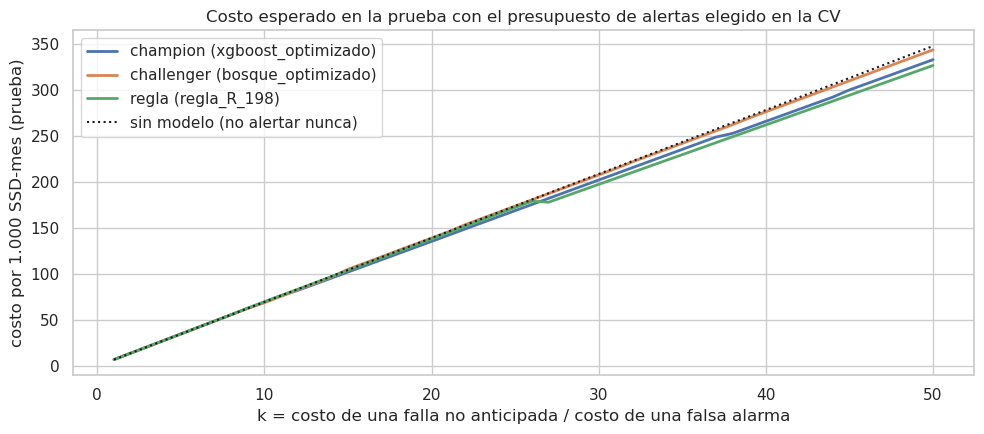

k de equilibrio frente a la regla (menor k desde el que el modelo cuesta menos): {'champion': 9.0, 'challenger': 9.0}


champion                                   challenger                                      regla                                  
           costo alertas_por_1000 alertas aciertos      costo alertas_por_1000 alertas aciertos    costo alertas_por_1000 alertas aciertos
k                                                                                                                                         
1.0000    6.9649           0.0000       0        0     6.9649           0.0000       0        0   6.9649           0.0000       0        0
5.0000   34.8455           0.0211       3        0    34.8244           0.0000       0        0  34.8244           0.0000       0        0
10.0000  69.6347           0.0633       9        1    68.8256           0.8020     114       21  69.8739           1.6181     230       18
20.0000 135.5829           2.4905     354       42   139.2623           4.1015     583       28 138.2563           1.6181     230       18
30.0000 202.4035           2.6171     372       42   207.9121           5.0724     721       28 197.6477           3.9679     564       70
50.0000 333.3854           4.5166     642       54   344.1141           6.9930     994       31 327.0959           3.9679     564       70

In [9]:
COSTOS = {rol: pl.costo_con_presupuesto(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], prueba["DAYS_TO_FAILURE"],
                                        SCORES[rol], PRESUP_K[rol]) for rol in MODELOS}
fig, ax = plt.subplots(figsize=(10, 4.5))
for rol, c in COSTOS.items():
    ax.plot(c["k"], c["costo"], label=f"{rol} ({ELEGIDOS.get(rol, regla_nombre)})", lw=2)
ax.plot(COSTOS["regla"]["k"], COSTOS["regla"]["costo_sin_modelo"], "k:", label="sin modelo (no alertar nunca)")
ax.set_xlabel("k = costo de una falla no anticipada / costo de una falsa alarma")
ax.set_ylabel("costo por 1.000 SSD-mes (prueba)")
ax.set_title("Costo esperado en la prueba con el presupuesto de alertas elegido en la CV")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "05_costo_vs_k.png", dpi=150); plt.show()

k_eq = {rol: pl.k_equilibrio(COSTOS[rol], COSTOS["regla"]) for rol in ELEGIDOS}
print("k de equilibrio frente a la regla (menor k desde el que el modelo cuesta menos):", k_eq)
tabla_k = pd.concat({rol: c.set_index("k")[["costo", "alertas_por_1000", "alertas", "aciertos"]] for rol, c in COSTOS.items()}, axis=1)
tabla_k.to_csv("../docs/costo_por_k.csv")
tabla_k.loc[[1, 5, 10, 20, 30, 50]]

## 6. Explicabilidad (valores SHAP)

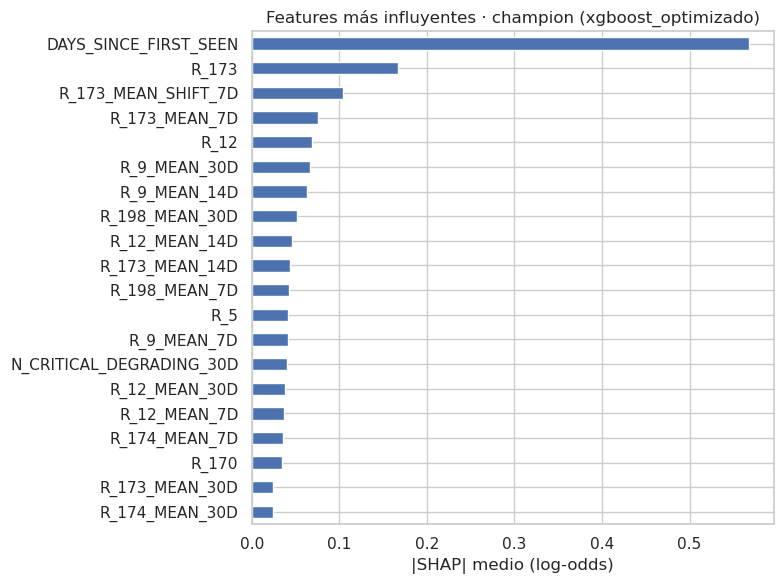

Alerta explicada: disco con score 0.8820 (τ 0.8351), falla 12 días después


,contribucion_log_odds,valor
DAYS_SINCE_FIRST_SEEN,0.4285,535.0000
R_198_MEAN_30D,0.3603,1.0000
R_198_MEAN_7D,0.3588,1.0000
N_CRITICAL_DEGRADING_30D,0.2136,NaN
R_5,0.1693,26.0000
R_198,0.1541,1.0000
R_170,0.1378,26.0000
R_173,-0.1042,1.0000
R_196,0.1000,26.0000
R_198_MEAN_14D,0.0560,1.0000


In [10]:
# XGBoost calcula valores SHAP exactos de sus árboles (pred_contribs) en GPU; se explica el primer modelo de árboles
import xgboost as xgb
rol_arbol = next((r for r in ("champion", "challenger") if ranking.loc[ELEGIDOS[r], "familia"] in {"xgboost", "bosque"}), None)
if rol_arbol is None:
    print("Ni el champion ni el challenger son de árboles: no se calculan valores SHAP exactos")
else:
    m = MODELOS[rol_arbol]
    nombres = list(COLUMNAS) + [pl.FEATURE_DEGRADACION]
    rng = np.random.default_rng(SEMILLA)
    pos_pos = np.flatnonzero(prueba["TARGET_30D"].to_numpy() == 1)
    muestra = np.concatenate([rng.choice(pos_pos, min(1000, len(pos_pos)), replace=False),
                              rng.choice(len(prueba), 4000, replace=False)])
    Xm = m.named_steps["prep"].transform(X_te.iloc[muestra])
    contrib = m.named_steps["modelo"].get_booster().predict(xgb.DMatrix(Xm), pred_contribs=True)[:, :-1]
    imp = pd.Series(np.abs(contrib).mean(0), index=nombres).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 6))
    imp.head(20)[::-1].plot.barh(ax=ax, color="#4C72B0")
    ax.set_xlabel("|SHAP| medio (log-odds)"); ax.set_title(f"Features más influyentes · {rol_arbol} ({ELEGIDOS[rol_arbol]})")
    fig.tight_layout(); fig.savefig(FIG / "05_shap_importancia.png", dpi=150); plt.show()
    # Un ejemplo: una alerta acertada (disco que falla 7–30 días después, con score ≥ τ)
    s, tau = SCORES[rol_arbol], TAU_TEST[rol_arbol]
    acierto = np.flatnonzero((s >= tau) & prueba["DAYS_TO_FAILURE"].between(7, 30).to_numpy())
    if len(acierto):
        i = acierto[np.argmax(s[acierto])]
        ci = m.named_steps["modelo"].get_booster().predict(
            xgb.DMatrix(m.named_steps["prep"].transform(X_te.iloc[[i]])), pred_contribs=True)[0, :-1]
        ej = pd.Series(ci, index=nombres).sort_values(key=np.abs, ascending=False).head(10)
        print(f"Alerta explicada: disco con score {s[i]:.4f} (τ {tau:.4f}), falla {prueba['DAYS_TO_FAILURE'].iloc[i]:.0f} días después")
        display(pd.DataFrame({"contribucion_log_odds": ej, "valor": X_te.iloc[i].reindex(ej.index)}))
    imp.head(15)

## 7. Registro: corridas finales, Model Registry y `corridas.csv`

In [11]:
VERSIONES = {}
for rol, nombre in ELEGIDOS.items():
    familia = ranking.loc[nombre, "familia"]
    fila = PRUEBA.loc[(rol, "todos")]
    metricas = {"test_pr_auc_evento": fila["pr_auc_evento"], "test_f05_evento": fila["f05_evento"],
                "test_precision_evento": fila["precision_evento"], "test_recall_evento": fila["recall_evento"],
                "test_pr_auc_evento_discos_no_vistos": PRUEBA.loc[(rol, "discos no vistos"), "pr_auc_evento"],
                "tau_operacion": TAU_TEST[rol], "presupuesto_alertas_por_1000": PRESUP_OP[rol],
                "test_alertas_por_1000": fila["alertas_por_1000"], "cv_pr_auc_evento_media": ranking.loc[nombre, "cv_media"],
                "cv_pr_auc_evento_std": ranking.loc[nombre, "cv_std"],
                "segundos_entrenamiento": TIEMPOS[rol]["entrenamiento_s"],
                "inferencia_s_por_millon": TIEMPOS[rol]["inferencia_s_por_millon"],
                "k_equilibrio_vs_regla": k_eq[rol] if k_eq[rol] is not None else np.nan}
    run_id = pl.registrar_corrida(
        nombre=f"final_{rol}_{familia}", fase="final", familia=familia, modelo=MODELOS[rol], seed=SEMILLA,
        metricas=metricas, datos=META_DATOS, X_ejemplo=X_te.head(5),
        params_extra={"frac_sanos_train": FRAC, "entrenamiento": "2018-01-03 a 2019-09-30",
                      "prueba": "2019-11-01 a 2019-11-30", "origen": nombre,
                      **{f"hp_{k}": v for k, v in (PARAMS[rol] or {}).items()}},
        tags_extra={"rol": rol, "corrida_cv": ranking.loc[nombre, "run_id"]})
    version = mlflow.register_model(f"runs:/{run_id}/pipeline", pl.NOMBRE_MODELO_REGISTRO)
    cliente.set_registered_model_alias(pl.NOMBRE_MODELO_REGISTRO, rol, version.version)
    VERSIONES[rol] = {"run_id": run_id, "version": version.version, "test_pr_auc_evento": fila["pr_auc_evento"]}
Path("../docs/registro.json").write_text(json.dumps({"modelo": pl.NOMBRE_MODELO_REGISTRO, **VERSIONES,
                                                     "dataset_sha256": manifiesto["dataset_sha256"]}, indent=2))
VERSIONES

2026/11/19 15:37:45 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 15:37:45 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 15:37:47 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/19 15:37:48 INFO mlflow.models.model: Found the following environment variables used during model inference: [ANTHROPIC_API_KEY, GEMINI_API_KEY]. Please check if you need to set them when deploying the model. To disable this message, set environment variable `MLFLOW_RECORD_ENV_VARS_IN_MODEL_LOGGING` to `false`.


Registered model 'ssd-failure-modelo' already exists. Creating a new version of this model...


🏃 View run final_champion_xgboost at: http://mlflow:5000/#/experiments/2/runs/ee39486d8f394a31898a059488f704eb
🧪 View experiment at: http://mlflow:5000/#/experiments/2


... (6 outputs left out)

2026/11/19 15:37:51 WARNING mlflow.tracking._model_registry.fluent: Run with id b69b085d65324ddb8a6b11aa65e7c5e8 has no artifacts at artifact path 'pipeline', registering model based on models:/m-be2be2269a634662a1163d5db7645a95 instead


2026/11/19 15:37:51 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ssd-failure-modelo, version 6


Created version '6' of model 'ssd-failure-modelo'.


{'champion': {'run_id': 'ee39486d8f394a31898a059488f704eb',
  'version': '5',
  'test_pr_auc_evento': np.float64(0.01937829472098547)},
 'challenger': {'run_id': 'b69b085d65324ddb8a6b11aa65e7c5e8',
  'version': '6',
  'test_pr_auc_evento': np.float64(0.010644163292223395)}}

In [12]:
corridas = pl.exportar_corridas("../docs/corridas.csv")
print(f"docs/corridas.csv: {len(corridas)} corridas")
print(corridas["tags.fase"].value_counts().to_string())
print(f"Tiempo total del notebook: {(time.time()-T0)/60:.1f} min")

docs/corridas.csv: 192 corridas
tags.fase
tuning       172
candidato     11
final          6
baseline       3
Tiempo total del notebook: 23.8 min


## 8. Conclusiones

| # | Pregunta | Evidencia | Conclusión |
|---|---|---|---|
| 1 | ¿La diferencia entre champion y challenger supera la variación entre pliegues? | CV: XGBoost 0,0205 ± 0,0192 y bosque 0,0203 ± 0,0174. Diferencia: 0,0003 | **No.** Es un empate. XGBoost queda como champion solo por la regla fijada de antemano (mayor media; `docs/plan_evaluacion_final.md`) |
| 2 | ¿Qué pasó en la prueba (nov-2019, 990 eventos)? | PR-AUC por evento: champion 0,0194, challenger 0,0106 y regla 0,0102. En su punto de operación: el champion acierta 42 en 354 alertas (precisión 0,119, recall 4,2 %, F0,5 0,087), el challenger 28 en 557 (F0,5 0,044) y la regla 18 en 230 (F0,5 0,047) | **El champion casi duplica a la regla y al challenger** en PR-AUC y en F0,5 por evento, y anticipa 2,3 veces más fallas que la regla. Aun así, anticipa menos del 5 % de las fallas |
| 3 | ¿Y al mismo presupuesto de alertas? | Con 1 alerta por 1.000 SSD-mes, el champion acierta 33 en 142 alertas (precisión 0,23) y la regla 8 en 89. Con 2,55, 42 contra 18. Con 5 o más, la regla acierta 70 en 564 (precisión 0,12) y el champion 54 en 676 (0,08) | **Con presupuestos bajos (hasta ~4 alertas por 1.000 SSD-mes) el champion es mejor que la regla. Con presupuestos altos, la regla es mejor.** Los scores de los árboles tienen muchos empates: el champion emite 462 alertas con 3,46 y con 3,94, y 676 con 5 y con 10. Para él, "mismo presupuesto" es una cota superior, no una igualdad |
| 4 | ¿Cuándo conviene anticipar? | El champion alerta 58 discos que fallan: 42 en la ventana útil de 7 a 30 días, 3 tarde y 13 antes de tiempo, con una mediana de 14 días. La regla alerta 68, pero 46 antes de los 30 días (mediana de 32) y solo 18 en la ventana | La regla detecta discos que van a fallar, pero demasiado pronto para la ventana de reemplazo. El champion concentra sus alertas en la ventana útil |
| 5 | Métrica de negocio (costo por 1.000 SSD-mes) | k ≤ 8: nadie mejora a no alertar (diferencias < 0,1 %). k de 9 a 11: gana el challenger por poco (k = 10: 68,8 contra 69,6 sin modelo). k de 12 a 26: gana el champion (k = 20: 135,6 contra 138,3 de la regla y 139,3 sin modelo, un 2,7 % de ahorro). k ≥ 27: gana la regla (k = 50: 327,1 contra 333,4 del champion y 348,2 sin modelo) | `k_equilibrio = 9` para los dos modelos. El champion es la opción más barata para k entre 12 y 26, y la regla desde k = 27. El mejor ahorro frente a no alertar nunca supera el 6 % |
| 6 | Costo de cómputo y explicabilidad | Entrenamiento: 362 s (champion) y 393 s (challenger). Inferencia: 4,2 y 4,0 s por millón de filas. Ambos son árboles con valores SHAP exactos. La alerta explicada (sección 6) se apoya en la edad del disco y en R_198 | No hay diferencia práctica entre los dos modelos. La regla es la más barata y la más explicable |

**Decisión (propuesta, pendiente de confirmar por el equipo).**
- XGBoost optimizado queda como `@champion` (versión 5) y el bosque optimizado como `@challenger` (versión 6). Es lo
  que dice la regla de selección fijada antes de usar la prueba.
- En la prueba, el champion supera a la regla R_198:
  - en PR-AUC por evento (0,0194 contra 0,0102);
  - en su punto de operación;
  - con presupuestos bajos de alertas;
  - en costo para k entre 12 y 26.
- La regla sigue siendo mejor con presupuestos altos y para k ≥ 27, y en la CV la diferencia no supera la desviación
  entre pliegues.
- Se propone usar el champion **con un presupuesto bajo de alertas** (≤ 2,5 por 1.000 SSD-mes, su punto de operación de
  la CV) y mantener la regla como referencia hasta confirmarlo en otro período (PSet #4).

**Limitaciones de esta evaluación.**

- **La prueba se evaluó tres veces.** Las reglas de selección y de umbral de la tercera quedaron fijadas por escrito
  antes de correrla (`docs/plan_evaluacion_final.md`, commit `493d836`).
  1. Commit `a367744`: se aplicó en la prueba el τ de la CV.
  2. Commit `6cb8588`: al ver que el champion casi no alertaba, se cambió a presupuestos de alertas (sección 2).
  3. Commit `493d836`: ronda final, con el tuning rehecho para que las tres familias tuvieran 30 configuraciones
     completas y sin corridas `-dirty`.

  La ronda final cambió los hiperparámetros del champion y su PR-AUC de prueba pasó de 0,0075 a 0,0194. Sin embargo,
  el tuning se rehízo para completar el protocolo, no por lo que mostró la prueba, y la regla de selección no cambió.
  Aun así, la prueba ya no es del todo nueva y los números de prueba deben leerse como optimistas en esa medida.
  `docs/corridas.csv` tiene seis corridas `fase=final`. Las cuatro de las rondas 1 y 2 llevan el tag
  `estado=reemplazada` (`scripts/marcar_finales_reemplazadas.py`).
- **No hay discos nuevos con falla en la prueba** (0 eventos entre los discos no vistos): no se puede medir cómo
  generaliza el modelo a discos que no estaban en entrenamiento.
- **Un solo mes de prueba.** La CV mostró desviaciones entre pliegues del mismo tamaño que las medias: un mes distinto
  podría ordenar los modelos de otra forma. Diciembre de 2019 no sirve como segunda prueba: tiene 168 mil filas
  etiquetadas contra 4,3 millones en noviembre, por la censura de la etiqueta de 30 días.
- **Corridas reemplazadas.** De las 192 corridas de `docs/corridas.csv`, 72 llevan `estado=reemplazada`:
  - los estudios originales del bosque y la MLP, con poda y con commits `-dirty`;
  - repeticiones de corridas;
  - las finales anteriores.

  Ninguna de las 120 corridas vigentes tiene el commit marcado `-dirty`.
